# Regresión logística binaria desde cero

Este cuaderno ajusta una regresión logística binaria escrita desde cero.

1. Generar dos clases en el plano.
2. Escribir el modelo, la log verosimilitud negativa y su gradiente.
3. Ajustar por descenso de gradiente y por el método de Newton (mínimos cuadrados reponderados).
4. Dibujar la frontera y las probabilidades, y evaluar en datos nuevos.
5. Obtener fronteras curvas agregando variables transformadas.
6. Repetir el ajuste con PyTorch y verificar con scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (6, 4.5), "font.size": 12, "axes.grid": True, "grid.alpha": 0.25})
AZUL, ROJO = "#3C72E8", "#8C1515"
rng = np.random.default_rng(0)

## Datos

Dos nubes normales que se traslapan. La clase 1 (cuadrados rojos) está centrada en $(2, 2)$ y la clase 0
(círculos azules) en $(0, 0)$. Se separan 200 puntos para entrenar y 1 000 para evaluar.

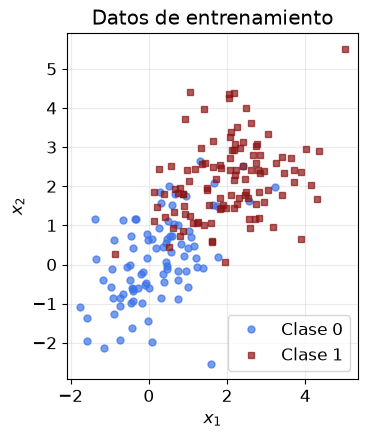

In [2]:
def simula(n, rng):
    y = rng.integers(0, 2, n)
    centros = np.array([[0.0, 0.0], [2.0, 2.0]])
    S = np.array([[1.0, 0.4], [0.4, 1.0]])
    X = centros[y] + rng.multivariate_normal([0, 0], S, n)
    return X, y.astype(float)

X_tr, y_tr = simula(200, rng)
X_te, y_te = simula(1000, rng)

def dibuja(ax, X, y):
    ax.plot(*X[y == 0].T, "o", ms=5, color=AZUL, alpha=0.7, label="Clase 0")
    ax.plot(*X[y == 1].T, "s", ms=5, color=ROJO, alpha=0.7, label="Clase 1")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")

fig, ax = plt.subplots()
dibuja(ax, X_tr, y_tr); ax.legend(); ax.set_title("Datos de entrenamiento")
plt.show()

## El modelo

El modelo calcula un puntaje lineal $z = \beta_0 + \beta_1x_1 + \beta_2x_2$ y lo convierte en probabilidad
con la sigmoide,
$$p(\mathbf{x}) = \Pr(y = 1 \mid \mathbf{x}) = \mathrm{sig}(z) = \frac{1}{1 + e^{-z}} .$$

Con una columna de unos en $\mathbf{X}$ para el intercepto, la log verosimilitud negativa media y su
gradiente son
$$\ell(\boldsymbol\beta) = \frac{1}{n}\sum_{i=1}^{n}\Big[\log\big(1 + e^{z_i}\big) - y_iz_i\Big], \qquad
\nabla\ell(\boldsymbol\beta) = \frac{1}{n}\mathbf{X}^\top(\mathbf{p} - \mathbf{y}).$$

`np.logaddexp(0, z)` calcula $\log(1 + e^{z})$ sin desbordarse cuando $z$ es grande.

In [3]:
def con_unos(X):
    return np.column_stack([np.ones(len(X)), X])

def sig(z):
    return 0.5*(1 + np.tanh(0.5*z))              # igual a 1/(1 + e^{-z}), estable para |z| grande

def perdida(b, X, y):
    z = X @ b
    return np.mean(np.logaddexp(0, z) - y*z)

def gradiente(b, X, y):
    return X.T @ (sig(X @ b) - y)/len(y)

A_tr, A_te = con_unos(X_tr), con_unos(X_te)

Antes de optimizar conviene verificar el gradiente con diferencias finitas. Si la fórmula está bien,
la diferencia es del orden de $10^{-9}$ o menor.

In [4]:
b_prueba = rng.normal(size=3); h = 1e-6
num = np.array([(perdida(b_prueba + h*e, A_tr, y_tr) - perdida(b_prueba - h*e, A_tr, y_tr))/(2*h) for e in np.eye(3)])
print("Gradiente analítico:", gradiente(b_prueba, A_tr, y_tr))
print("Diferencias finitas:", num)
print("Máxima diferencia:  ", np.max(np.abs(num - gradiente(b_prueba, A_tr, y_tr))))

Gradiente analítico: [ 0.02528915 -0.6576427  -0.77335907]
Diferencias finitas: [ 0.02528915 -0.6576427  -0.77335907]
Máxima diferencia:   1.3931500397745822e-10


## Descenso de gradiente

Cada paso mueve los coeficientes en contra del gradiente, $\boldsymbol\beta \leftarrow \boldsymbol\beta - \eta\,\nabla\ell(\boldsymbol\beta)$.
El punto $i$ aporta $(p_i - y_i)\,\mathbf{x}_i$, de modo que los puntos con probabilidad muy equivocada
mueven más la frontera.

In [5]:
def descenso(X, y, eta=0.5, iteraciones=2000):
    b = np.zeros(X.shape[1]); historia = []
    for _ in range(iteraciones):
        historia.append(perdida(b, X, y))
        b = b - eta*gradiente(b, X, y)
    return b, np.array(historia)

b_gd, h_gd = descenso(A_tr, y_tr)
print("Coeficientes por descenso de gradiente:", b_gd)

Coeficientes por descenso de gradiente: [-2.68986472  1.05074734  1.49613462]


## Método de Newton (mínimos cuadrados reponderados)

El hessiano es $\nabla^2\ell = \frac{1}{n}\mathbf{X}^\top\mathbf{W}\mathbf{X}$, con $\mathbf{W} = \operatorname{diag}\big(p_i(1 - p_i)\big)$.
El paso de Newton usa la curvatura y converge en pocas iteraciones,
$$\boldsymbol\beta \leftarrow \boldsymbol\beta + \big(\mathbf{X}^\top\mathbf{W}\mathbf{X}\big)^{-1}\mathbf{X}^\top(\mathbf{y} - \mathbf{p}).$$
Cada paso equivale a una regresión por mínimos cuadrados ponderados, y por eso el método se llama IRLS.

Coeficientes por Newton: [-2.68986473  1.05074734  1.49613462]  iteraciones: 8


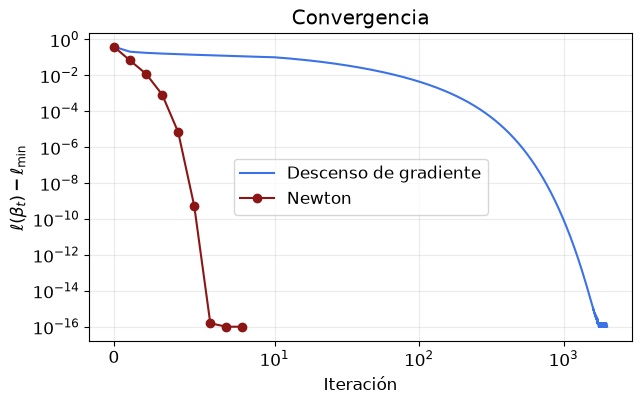

In [6]:
def newton(X, y, iteraciones=25, tol=1e-12):
    b = np.zeros(X.shape[1]); historia = [perdida(b, X, y)]
    for _ in range(iteraciones):
        p = sig(X @ b); w = p*(1 - p)
        paso = np.linalg.solve(X.T @ (X*w[:, None]), X.T @ (y - p))
        b = b + paso; historia.append(perdida(b, X, y))
        if np.max(np.abs(paso)) < tol:
            break
    return b, np.array(historia)

b_nw, h_nw = newton(A_tr, y_tr)
print("Coeficientes por Newton:", b_nw, " iteraciones:", len(h_nw) - 1)

l_min = h_nw[-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(len(h_gd)), h_gd - l_min + 1e-16, color=AZUL, label="Descenso de gradiente")
ax.semilogy(np.arange(len(h_nw)), h_nw - l_min + 1e-16, "o-", color=ROJO, label="Newton")
ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("Iteración"); ax.set_ylabel(r"$\ell(\beta_t) - \ell_{\min}$")
ax.legend(); ax.set_title("Convergencia")
plt.show()

Newton llega a la precisión de máquina en unas pocas iteraciones. El descenso de gradiente necesita
cientos o miles de pasos, según la tasa $\eta$.

## La frontera y las probabilidades

La frontera $p = 1/2$ es la recta $z = 0$. Las curvas de nivel de $p$ son rectas paralelas a ella.

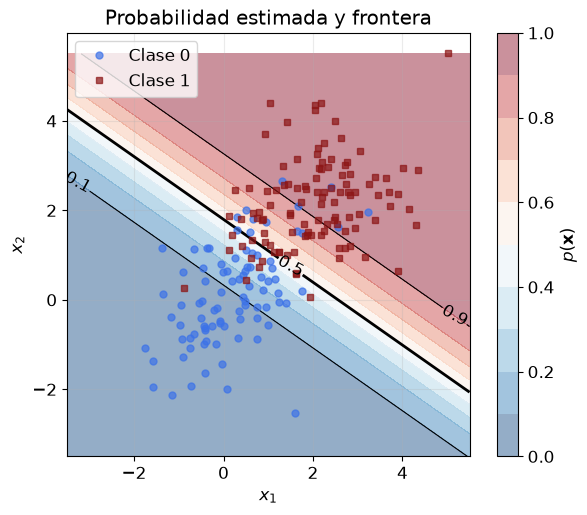

In [7]:
g1, g2 = np.meshgrid(np.linspace(-3.5, 5.5, 300), np.linspace(-3.5, 5.5, 300))
P = sig(con_unos(np.column_stack([g1.ravel(), g2.ravel()])) @ b_nw).reshape(g1.shape)
fig, ax = plt.subplots(figsize=(7, 5.5))
cf = ax.contourf(g1, g2, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.45)
cs = ax.contour(g1, g2, P, levels=[0.1, 0.5, 0.9], colors="k", linewidths=[0.8, 2, 0.8])
ax.clabel(cs, fmt="%.1f")
dibuja(ax, X_tr, y_tr); ax.legend(loc="upper left")
fig.colorbar(cf, ax=ax, label=r"$p(\mathbf{x})$")
ax.set_title("Probabilidad estimada y frontera")
plt.show()

## Interpretación y errores estándar

$e^{\beta_j}$ es la razón de chances de la variable $j$: si $x_j$ sube una unidad y la otra queda fija, las
chances se multiplican por $e^{\beta_j}$. La covarianza aproximada de $\hat{\boldsymbol\beta}$ es la inversa del
hessiano en el óptimo, $(\mathbf{X}^\top\hat{\mathbf{W}}\mathbf{X})^{-1}$.

In [8]:
p = sig(A_tr @ b_nw)
cov = np.linalg.inv(A_tr.T @ (A_tr*(p*(1 - p))[:, None]))
ee = np.sqrt(np.diag(cov))
for nom, b_, e_ in zip(["Intercepto", "x1", "x2"], b_nw, ee):
    print(f"{nom:>10}: beta = {b_:6.3f}, EE = {e_:.3f}, z = {b_/e_:6.2f}, razón de chances = {np.exp(b_):6.2f}")

Intercepto: beta = -2.690, EE = 0.456, z =  -5.90, razón de chances =   0.07
        x1: beta =  1.051, EE = 0.279, z =   3.76, razón de chances =   2.86
        x2: beta =  1.496, EE = 0.310, z =   4.83, razón de chances =   4.46


## Evaluación en datos nuevos

Con el umbral $1/2$ se cuenta la matriz de confusión. La curva ROC recorre todos los umbrales, y el área
bajo ella (AUC) es la fracción de pares positivo–negativo en que el positivo recibe mayor probabilidad.

VP = 436, FN = 71, FP = 59, VN = 434
Exactitud = 0.870, sensibilidad = 0.860, especificidad = 0.880


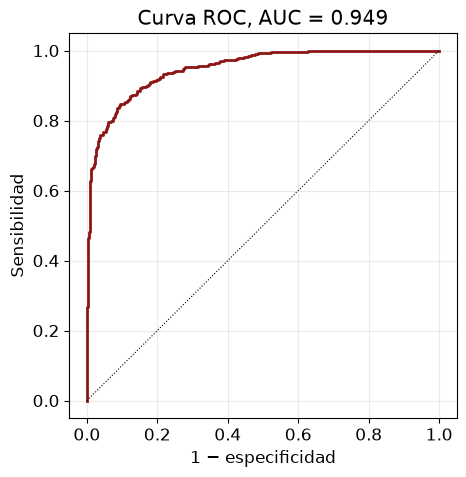

Log verosimilitud negativa media en test: 0.28863229581235006


In [9]:
p_te = sig(A_te @ b_nw); yhat = (p_te > 0.5).astype(float)
VP = np.sum((yhat == 1) & (y_te == 1)); FN = np.sum((yhat == 0) & (y_te == 1))
FP = np.sum((yhat == 1) & (y_te == 0)); VN = np.sum((yhat == 0) & (y_te == 0))
print(f"VP = {VP}, FN = {FN}, FP = {FP}, VN = {VN}")
print(f"Exactitud = {(VP + VN)/len(y_te):.3f}, sensibilidad = {VP/(VP + FN):.3f}, especificidad = {VN/(VN + FP):.3f}")

def roc(y, s):
    umbrales = np.sort(np.unique(s))[::-1]
    tpr = [0.0] + [np.mean(s[y == 1] >= c) for c in umbrales]
    fpr = [0.0] + [np.mean(s[y == 0] >= c) for c in umbrales]
    return np.array(fpr), np.array(tpr)

def auc(y, s):
    pos, neg = s[y == 1], s[y == 0]
    return np.mean(pos[:, None] > neg[None, :]) + 0.5*np.mean(pos[:, None] == neg[None, :])

fpr, tpr = roc(y_te, p_te)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color=ROJO, lw=2); ax.plot([0, 1], [0, 1], "k:", lw=0.8)
ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad"); ax.set_title(f"Curva ROC, AUC = {auc(y_te, p_te):.3f}")
plt.show()
print("Log verosimilitud negativa media en test:", perdida(b_nw, A_te, y_te))

## Fronteras curvas con variables transformadas

El modelo es lineal en los coeficientes, no necesariamente en las variables. Si una clase rodea a la otra,
una recta no sirve, pero agregar $x_1^2$, $x_2^2$ y $x_1x_2$ permite fronteras cuadráticas, como una elipse.
El mismo código de Newton ajusta el modelo ampliado.

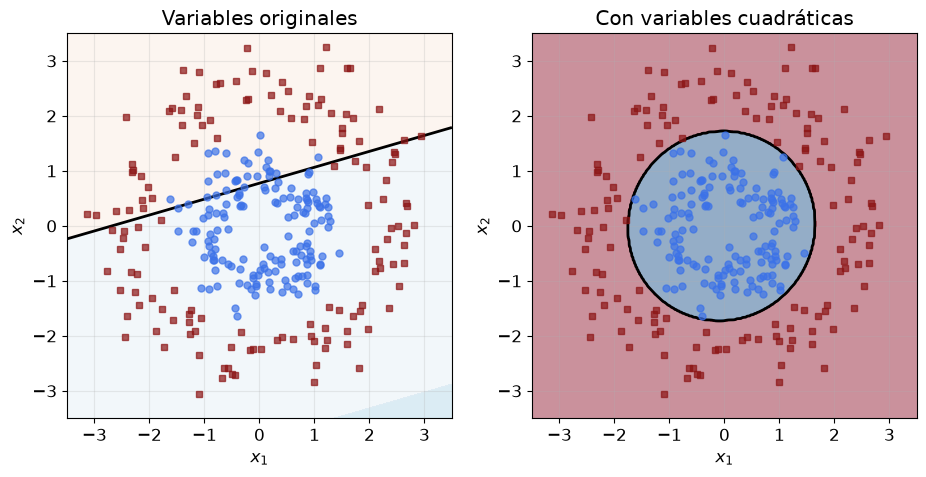

Error de entrenamiento del modelo lineal: 0.370
Error de entrenamiento del modelo cuadrático: 0.000


In [10]:
n = 300
r_ = np.where(rng.uniform(size=n) < 0.5, rng.normal(1.0, 0.3, n), rng.normal(2.4, 0.4, n))
ang = rng.uniform(0, 2*np.pi, n)
X_an = np.column_stack([r_*np.cos(ang), r_*np.sin(ang)]); y_an = (r_ > 1.7).astype(float)

def cuadraticas(X):
    return np.column_stack([X, X[:, 0]**2, X[:, 1]**2, X[:, 0]*X[:, 1]])

b_lin, _ = newton(con_unos(X_an), y_an)
b_cua, _ = newton(con_unos(cuadraticas(X_an)), y_an)
g1, g2 = np.meshgrid(np.linspace(-3.5, 3.5, 300), np.linspace(-3.5, 3.5, 300)); G = np.column_stack([g1.ravel(), g2.ravel()])
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, (P_, tit) in zip(ax, [(sig(con_unos(G) @ b_lin), "Variables originales"), (sig(con_unos(cuadraticas(G)) @ b_cua), "Con variables cuadráticas")]):
    a.contourf(g1, g2, P_.reshape(g1.shape), levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.45)
    a.contour(g1, g2, P_.reshape(g1.shape), levels=[0.5], colors="k", linewidths=2)
    dibuja(a, X_an, y_an); a.set_title(tit)
plt.show()
for nom, X_, b_ in [("lineal", con_unos(X_an), b_lin), ("cuadrático", con_unos(cuadraticas(X_an)), b_cua)]:
    print(f"Error de entrenamiento del modelo {nom}: {np.mean((sig(X_ @ b_) > 0.5) != y_an):.3f}")

## El mismo modelo en PyTorch

PyTorch calcula el gradiente por diferenciación automática. `BCEWithLogitsLoss` recibe el puntaje $z$ y
calcula la misma log verosimilitud negativa media, en forma estable.

In [11]:
import torch

torch.manual_seed(0)
Xt = torch.tensor(X_tr, dtype=torch.float64); yt = torch.tensor(y_tr, dtype=torch.float64)
modelo = torch.nn.Linear(2, 1).double()
torch.nn.init.zeros_(modelo.weight); torch.nn.init.zeros_(modelo.bias)
opt = torch.optim.LBFGS(modelo.parameters(), lr=1, max_iter=200, tolerance_grad=1e-12, tolerance_change=1e-14,
                        line_search_fn="strong_wolfe")
fn_perdida = torch.nn.BCEWithLogitsLoss()

def cierre():
    opt.zero_grad()
    l = fn_perdida(modelo(Xt).squeeze(1), yt)
    l.backward()
    return l

opt.step(cierre)
b_torch = np.r_[modelo.bias.detach().numpy(), modelo.weight.detach().numpy().ravel()]
print("PyTorch:", b_torch)
print("Newton: ", b_nw)

PyTorch: [-2.68986477  1.05074738  1.49613465]
Newton:  [-2.68986473  1.05074734  1.49613462]


## Verificación con scikit-learn

`LogisticRegression` penaliza por defecto con L2, con intensidad $1/C$. Con `C=np.inf` ajusta la máxima
verosimilitud sin penalización, que es lo que se programó arriba.

In [12]:
from sklearn.linear_model import LogisticRegression

sk = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10000).fit(X_tr, y_tr)
b_sk = np.r_[sk.intercept_, sk.coef_.ravel()]
print("scikit-learn:", b_sk)
print("Máxima diferencia con Newton:", np.max(np.abs(b_sk - b_nw)))

scikit-learn: [-2.68986474  1.05074734  1.49613463]
Máxima diferencia con Newton: 8.46094216910842e-09


## Ejercicios

1. Cambie la tasa $\eta$ del descenso de gradiente a $0{,}05$ y a $5$. ¿Qué pasa con la convergencia?
2. Aleje las nubes hasta que las clases queden separadas sin error. ¿Qué pasa con los coeficientes de
   Newton y con sus errores estándar? Agregue una penalización ridge, $\frac{\lambda}{2}\|\boldsymbol\beta\|^2$ sin el intercepto,
   al gradiente y al hessiano, y repita.
3. Con los datos de evaluación, busque el umbral que minimiza el costo si un falso negativo cuesta diez
   veces más que un falso positivo, y compárelo con $1/11$.